# Spatial QC — mouse

Removes **positions**, never cells. A cell with an untrustworthy coordinate gets
its coordinate set to `NaN`, joining the ~49% of cells that never had one — a
category every spatial analysis already handles via `notna()`. So the expression
pipeline (integrate → annotate → reintegrate → DE) is untouched and cell counts
still reconcile against the published totals.

**Stages**, in order — each reported separately:

| stage | what it catches | why |
|---|---|---|
| `unmapped` | no coordinate to begin with | normal for Slide-tags; kept as-is |
| `degenerate` | exact duplicate coords, or kNN mean distance < 10 µm | cells ~10 µm and beads ~10 µm apart, so sub-10 µm spacing between *distinct* cells is physically impossible. Must run **before** the MAD — a pile-up drags the median down and inflates the MAD (one puck's threshold went 6391 µm → 440 µm once removed) |
| `far` | kNN mean distance above median + 3·MAD on **log** scale, per timepoint | distances are right-skewed, so raw-scale MAD over-cuts (10–12% vs 5%); recomputed on survivors |
| `boxed` | hand-drawn regions the statistics miss | residual clumps that are internally dense, so no distance rule sees them |

Then coordinates are **rotated per puck** so tissue is consistently oriented.

Duplicate detection is per **sample** (pucks are separate coordinate frames, so a
shared coordinate across replicates is coincidence); the MAD is per **timepoint**
(pooling replicates sets the threshold from the healthier puck — only 0.35% of
cells change fate versus per-sample, and the tighter threshold is the better one).

## 1. Config — everything tunable lives here

In [1]:
SPECIES = "mouse"                    # human: fill in ROTATIONS/EXCLUSIONS below
REPO    = "/n/eddy_lab/users/nhilgert/xmens_final"
SUB     = "/n/eddy_lab/users/nhilgert/decidualization/revisions/adatas/submission"
REF_ALL = {"mouse": "20251008_Cevrim_XMens_All_Cells.h5ad",
           "human": "20251008_Cevrim_Human_All_Cells.h5ad"}
REF_FINE = {"mouse": "20251008_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad"}   # mouse only

X, Y = "x_um_dbscan", "y_um_dbscan"
SAMPLE, TIMEPOINT = "sample", "timepoint"

K            = 5        # neighbours for the mean-distance score
FLOOR_UM     = 10.0     # physical floor -- below this is not a real position
MAX_AT_COORD = 1        # >1 cell at an identical coordinate = degenerate
N_MADS       = 3.0      # upper cut, on log(distance)
MAD_GROUP    = TIMEPOINT   # MAD grouped by timepoint; duplicates always per sample

TP_ORDER = {"mouse": ["uninduced","1_dpi_early","1_dpi_late","2_dpi","3_dpi","4_dpi_bleeding"],
            "human": []}

# hand-drawn regions the statistics miss. keys: timepoint|sample + x_gt/x_lt/y_gt/y_lt
EXCLUSIONS = {"mouse": [
    {"timepoint": "uninduced",   "y_gt": 5000},
    {"timepoint": "uninduced",   "x_lt": 500},
    {"timepoint": "uninduced",   "y_lt": 1500, "x_lt": 3000},
    {"timepoint": "uninduced",   "x_gt": 2500, "x_lt": 3000, "y_gt": 1500, "y_lt": 2000},
    {"timepoint": "1_dpi_early", "x_lt": 750},
    # 1_dpi_late: clean
    {"timepoint": "2_dpi",       "y_gt": 7000},
    {"timepoint": "3_dpi",       "y_gt": 9000},
    {"timepoint": "3_dpi",       "y_lt": 1500, "x_gt": 6500},
    # NOTE no box for the 3_dpi central island: denser than surrounding tissue,
    # normal QC, transcriptionally coherent -> a real spatial domain, kept.
], "human": []}

# degrees, counter-clockwise, applied about each PUCK's own post-QC centre
ROTATIONS = {"mouse": {"uninduced": 0.0, "1_dpi_early": 104.0, "1_dpi_late": 0.0,
                       "2_dpi": 240.3, "3_dpi": 210.0, "4_dpi_bleeding": 0.0},
             "human": {}}

OUT_H5AD = f"data/interim/qc_spatial_{SPECIES}.h5ad"

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scanpy as sc, json
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.neighbors import NearestNeighbors
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60)

REPO, SUB = Path(REPO), Path(SUB)
adata = sc.read_h5ad(REPO/f"data/interim/qc_passed_{SPECIES}.h5ad")
obs = adata.obs
TPS = [t for t in TP_ORDER[SPECIES] if t in set(obs[TIMEPOINT].astype(str))]
EXCL, ROT = EXCLUSIONS[SPECIES], ROTATIONS[SPECIES]
print(f"{SPECIES}: {adata.n_obs:,} cells x {adata.n_vars:,} genes")
print(obs.groupby([TIMEPOINT, SAMPLE], observed=True).size().to_string())

def knn_mean_dist(xy, k=K):
    if xy.shape[0] <= k + 1: return np.zeros(xy.shape[0])
    nn = NearestNeighbors(n_neighbors=k + 1).fit(xy)
    d, _ = nn.kneighbors(xy)
    return d[:, 1:].mean(axis=1)

mouse: 68,069 cells x 33,698 genes
timepoint       sample               
1_dpi_early     1_dpi_early_mck1          3458
1_dpi_late      1_dpi_late_mck12a         7497
                1_dpi_late_mck12b         6860
2_dpi           2_dpi_mck15               5014
3_dpi           3_dpi_mck10a              8273
                3_dpi_mck10b              8196
4_dpi_bleeding  4_dpi_bleeding_mck11a     8433
uninduced       uninduced_mck8a          11892
                uninduced_mck8b           8446


## 2. Stage `unmapped` — who has a coordinate at all?

Roughly half of Slide-tags cells never localise. They are **not** filtered: they
have no position to be wrong about, and their expression is normal (~0.9× on
genes and counts vs mapped cells).

In [3]:
reason = pd.Series("kept", index=obs.index, dtype=object)
mapped = (obs[X].notna() & obs[Y].notna()).values
reason[~mapped] = "unmapped"
print(f"unmapped {int((~mapped).sum()):,} / {len(obs):,} ({100*(~mapped).mean():.1f}%)")
print(obs.loc[~mapped].groupby(TIMEPOINT, observed=True).size().to_string())

unmapped 33,609 / 68,069 (49.4%)
timepoint
1_dpi_early        1683
1_dpi_late         6923
2_dpi              2105
3_dpi              7771
4_dpi_bleeding     2437
uninduced         12690


## 3. Stage `degenerate` — impossible positions

Exact coordinate duplicates (per sample) plus anything below the physical floor.
Runs first so it cannot corrupt the MAD downstream.

In [4]:
score0 = pd.Series(np.nan, index=obs.index)
for s in obs.loc[mapped, SAMPLE].astype(str).unique():
    m = mapped & (obs[SAMPLE].astype(str) == s).values
    score0.loc[m] = knn_mean_dist(obs.loc[m, [X, Y]].to_numpy(float))

key = (obs[SAMPLE].astype(str) + "|" + obs[X].astype(str) + "|" + obs[Y].astype(str))
n_at = key.map(key[mapped].value_counts()).fillna(0)
degen = mapped & ((n_at > MAX_AT_COORD).values | (score0 < FLOOR_UM).values)
reason[degen] = "degenerate"
print(f"degenerate {int(degen.sum()):,}  "
      f"(exact dups {int((mapped & (n_at > MAX_AT_COORD).values).sum()):,}, "
      f"< {FLOOR_UM}um {int((mapped & (score0 < FLOOR_UM).values).sum()):,})")
if degen.any():
    print("\nlargest pile-ups:")
    print(obs.loc[degen].groupby([SAMPLE, X, Y], observed=True).size()
          .sort_values(ascending=False).head(5).to_string())
    print("\nby sample:"); print(obs.loc[degen].groupby(SAMPLE, observed=True).size().to_string())

degenerate 1,592  (exact dups 1,250, < 10.0um 1,545)

largest pile-ups:
sample             x_um_dbscan  y_um_dbscan
1_dpi_late_mck12b  734.562500   125.931570     202
2_dpi_mck15        4791.318000  6943.167000     90
1_dpi_late_mck12b  736.961071   126.117616      56
                   736.661250   126.094360      45
                   736.428056   126.076272      43

by sample:
sample
1_dpi_early_mck1        1
1_dpi_late_mck12a      30
1_dpi_late_mck12b    1279
2_dpi_mck15           101
3_dpi_mck10a           46
3_dpi_mck10b            3
uninduced_mck8a       115
uninduced_mck8b        17


## 4. Stage `far` — upper tail, recomputed on survivors

Removing the degenerate cells changes everyone's neighbours, so the score is
recomputed before thresholding.

In [5]:
surv = mapped & ~degen
score = pd.Series(np.nan, index=obs.index); thr = {}
for g in obs.loc[surv, MAD_GROUP].astype(str).unique():
    m = surv & (obs[MAD_GROUP].astype(str) == g).values
    d = knn_mean_dist(obs.loc[m, [X, Y]].to_numpy(float)); score.loc[m] = d
    lv = np.log1p(d); med = np.median(lv); mad = np.median(np.abs(lv - med))
    thr[g] = float(np.expm1(med + N_MADS * 1.4826 * mad))
    reason[m & (score > thr[g]).values] = "far"
print(pd.DataFrame({"threshold_um": pd.Series(thr).round(0),
                    "median_um": obs.assign(s=score).loc[surv]
                                 .groupby(MAD_GROUP, observed=True)["s"].median().round(1),
                    "dropped": pd.Series(reason[surv]).eq("far")
                               .groupby(obs.loc[surv, MAD_GROUP].astype(str)).sum()}).to_string())

                threshold_um  median_um  dropped
1_dpi_early            100.0       31.1       93
1_dpi_late             177.0       42.6       71
2_dpi                  269.0       75.7       15
3_dpi                  134.0       47.1      101
4_dpi_bleeding         224.0       76.0       39
uninduced              123.0       25.0      473


## 5. Stage `boxed` — hand-drawn regions

For clumps that are internally dense, so no distance rule sees them.

In [6]:
def rule_mask(r, base):
    m = base.copy()
    if "timepoint" in r: m &= (obs[TIMEPOINT].astype(str) == r["timepoint"]).values
    if "sample"    in r: m &= (obs[SAMPLE].astype(str) == r["sample"]).values
    for k_, col, op in [("x_gt", X, ">"), ("x_lt", X, "<"), ("y_gt", Y, ">"), ("y_lt", Y, "<")]:
        if k_ in r:
            m &= (obs[col] > r[k_]).values if op == ">" else (obs[col] < r[k_]).values
    return m

kept0 = (reason == "kept").values
boxed = np.zeros(len(obs), bool)
for r in EXCL:
    m = rule_mask(r, kept0); boxed |= m
    print(f"  {r}\n      -> {int(m.sum()):>5} cells")
reason[boxed] = "boxed"
print(f"\nboxed {int(boxed.sum()):,}")

  {'timepoint': 'uninduced', 'y_gt': 5000}
      ->    24 cells
  {'timepoint': 'uninduced', 'x_lt': 500}
      ->    19 cells
  {'timepoint': 'uninduced', 'y_lt': 1500, 'x_lt': 3000}
      ->    51 cells
  {'timepoint': 'uninduced', 'x_gt': 2500, 'x_lt': 3000, 'y_gt': 1500, 'y_lt': 2000}
      ->     5 cells
  {'timepoint': '1_dpi_early', 'x_lt': 750}
      ->     3 cells
  {'timepoint': '2_dpi', 'y_gt': 7000}
      ->     5 cells
  {'timepoint': '3_dpi', 'y_gt': 9000}
      ->    12 cells
  {'timepoint': '3_dpi', 'y_lt': 1500, 'x_gt': 6500}
      ->     6 cells

boxed 118


## 6. Blank — bad position becomes *no* position

In [7]:
ORDER = ["kept", "far", "degenerate", "boxed", "unmapped"]
COL = {"kept": "#7f9fc4", "far": "#DD8452", "degenerate": "#C44E52",
       "boxed": "#8172B3", "unmapped": "#dddddd"}
kept = (reason == "kept").values

x_qc = np.where(kept, obs[X].astype(float), np.nan)
y_qc = np.where(kept, obs[Y].astype(float), np.nan)

tal = reason.value_counts().reindex(ORDER).fillna(0).astype(int)
print(pd.DataFrame({"n": tal, "%": (100*tal/len(obs)).round(1)}).to_string())
print(f"\ncells with usable coordinates: {int(kept.sum()):,} "
      f"({100*kept.sum()/max(mapped.sum(),1):.1f}% of originally-mapped)")
print(f"cells in the object: {len(obs):,}  (unchanged -- nothing was removed)")
print("\nper timepoint:")
print(pd.crosstab(obs[TIMEPOINT].astype(str), reason).reindex(columns=ORDER, fill_value=0).to_string())

                n     %
kept        31958  46.9
far           792   1.2
degenerate   1592   2.3
boxed         118   0.2
unmapped    33609  49.4

cells with usable coordinates: 31,958 (92.7% of originally-mapped)
cells in the object: 68,069  (unchanged -- nothing was removed)

per timepoint:
col_0           kept  far  degenerate  boxed  unmapped
timepoint                                             
1_dpi_early     1678   93           1      3      1683
1_dpi_late      6054   71        1309      0      6923
2_dpi           2788   15         101      5      2105
3_dpi           8530  101          49     18      7771
4_dpi_bleeding  5957   39           0      0      2437
uninduced       6951  473         132     92     12690


## 7. Rotate — consistent tissue orientation

Angle per timepoint, **centre per puck** (pooling a timepoint's replicates would
put the centre in the gap between them), computed from post-QC cells only.
Rotation is rigid, so µm scale is preserved.

In [8]:
miss = set(obs[TIMEPOINT].astype(str).unique()) - set(ROT)
if miss: print(f"!! no angle for {sorted(miss)} -- defaulting to 0")

def rotate_about(x, y, deg, cx, cy):
    if deg % 360 == 0: return x.copy(), y.copy()
    r = np.radians(deg); ca, sa = np.cos(r), np.sin(r)
    dx, dy = x - cx, y - cy
    return cx + ca*dx - sa*dy, cy + sa*dx + ca*dy

x_rot, y_rot = x_qc.copy(), y_qc.copy()
rows = []
for s in obs.loc[mapped, SAMPLE].astype(str).unique():
    m  = mapped & (obs[SAMPLE].astype(str) == s).values
    mk = m & kept
    tp = obs.loc[m, TIMEPOINT].astype(str).iloc[0]
    deg = ROT.get(tp, 0.0)
    src = mk if mk.sum() >= 20 else m
    cx, cy = float(np.nanmedian(obs.loc[src, X])), float(np.nanmedian(obs.loc[src, Y]))
    nx, ny = rotate_about(x_qc[m], y_qc[m], deg, cx, cy)
    x_rot[m], y_rot[m] = nx, ny
    rows.append({"sample": s, "timepoint": tp, "deg": deg,
                 "n_kept": int(mk.sum()), "cx": round(cx), "cy": round(cy)})
print(pd.DataFrame(rows).to_string(index=False))
sp0 = np.hypot(np.nanstd(x_qc), np.nanstd(y_qc))
sp1 = np.hypot(np.nanstd(x_rot), np.nanstd(y_rot))
print(f"\nrigid check -- spread {sp0:.0f}um before, {sp1:.0f}um after")

               sample      timepoint   deg  n_kept   cx   cy
      uninduced_mck8a      uninduced   0.0    3636 3728 2446
      uninduced_mck8b      uninduced   0.0    3315 3755 2449
     1_dpi_early_mck1    1_dpi_early 104.0    1678 1886 1882
    1_dpi_late_mck12a     1_dpi_late   0.0    4276 3421 2930
    1_dpi_late_mck12b     1_dpi_late   0.0    1778 3187 3036
          2_dpi_mck15          2_dpi 240.3    2788 6143 3280
         3_dpi_mck10a          3_dpi 210.0    4002 5210 4731
         3_dpi_mck10b          3_dpi 210.0    4528 5159 4747
4_dpi_bleeding_mck11a 4_dpi_bleeding   0.0    5957 5544 6047

rigid check -- spread 2789um before, 2807um after


## 8. Sanity — what did we flag, and was it biased?

Joins the deposited labels to check we haven't wiped out a population. Expected:
perimetrium and smooth muscle are enriched among flagged cells (they sit at the
tissue edge and detach during dissociation) **without** a quality deficit.

In [11]:
# .map() on a categorical reference column returns a categorical, and you can't
# fillna it with a value that isn't already a category -- cast to object first.
coarse = mykey.map(cr.set_index("k")["cell_type_annotations"]).astype(object)
coarse = coarse.where(coarse.notna(), "unlabeled")
if SPECIES in REF_FINE and (SUB/REF_FINE[SPECIES]).exists():
    fr = sc.read_h5ad(SUB/REF_FINE[SPECIES], backed="r").obs.copy(); fr["k"] = _key(fr)
    fine = mykey.map(fr.set_index("k")["cell_subtype_annotations"]).astype(object)
    label = fine.where(fine.notna(), coarse)
else:
    label = coarse

In [13]:
def _canon(s):
    s = s.astype(str).str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
    return s.str.replace("bleeding", "menstrual", regex=False)
def _key(o):
    return _canon(o["sample"]) + "||" + \
           o["cell_barcode"].astype(str).str.replace(r"-\d+$", "", regex=True)

mykey = _key(obs)
cr = sc.read_h5ad(SUB/REF_ALL[SPECIES], backed="r").obs.copy(); cr["k"] = _key(cr)
# .map() on a categorical reference column returns a categorical, and you can't
# fillna it with a value that isn't already a category -- cast to object first.
coarse = mykey.map(cr.set_index("k")["cell_type_annotations"]).astype(object)
coarse = coarse.where(coarse.notna(), "unlabeled")
if SPECIES in REF_FINE and (SUB/REF_FINE[SPECIES]).exists():
    fr = sc.read_h5ad(SUB/REF_FINE[SPECIES], backed="r").obs.copy(); fr["k"] = _key(fr)
    fine = mykey.map(fr.set_index("k")["cell_subtype_annotations"]).astype(object)
    label = fine.where(fine.notna(), coarse)
else:
    label = coarse

flagged = mapped & ~kept
base = flagged[mapped].mean()
ct = pd.DataFrame({"mapped": pd.Series(coarse[mapped]).value_counts(),
                   "flagged": pd.Series(coarse[mapped & flagged]).value_counts()}).fillna(0)
ct["flagged_%"] = (100*ct.flagged/ct.mapped).round(1)
ct["enrichment"] = (ct.flagged/ct.mapped/base).round(2)
print(f"baseline flag rate among MAPPED cells: {100*base:.1f}%\n")
print(ct.sort_values("enrichment", ascending=False).to_string())

QC = [c for c in ["n_genes_by_counts","total_counts","doubletdetection_doublet_score"]
      if c in obs.columns]
print("\nquality, within cell type (ratio <1 = flagged cells are worse):")
rows = []
for t in ct.index:
    m = mapped & (coarse == t).values
    k_, f_ = obs.loc[m & kept, QC], obs.loc[m & flagged, QC]
    if len(f_) < 10 or len(k_) < 10: continue
    rows.append({"coarse": t, "n_flagged": len(f_),
                 **{c: round(float(f_[c].median()/max(k_[c].median(), 1e-9)), 2) for c in QC}})
print(pd.DataFrame(rows).set_index("coarse").to_string())

baseline flag rate among MAPPED cells: 7.3%

                         mapped  flagged  flagged_%  enrichment
perimetrium cells           259       66       25.5        3.51
smooth muscle cells         588      110       18.7        2.58
unlabeled                  3058      462       15.1        2.08
immune cells                934      101       10.8        1.49
epithelial cells           2819      294       10.4        1.44
endometrial fibroblasts   10609      754        7.1        0.98
vascular cells             2103       99        4.7        0.65
decidual cells            14090      616        4.4        0.60

quality, within cell type (ratio <1 = flagged cells are worse):
                         n_flagged  n_genes_by_counts  total_counts  doubletdetection_doublet_score
coarse                                                                                             
decidual cells                 616               0.85          0.74                            0.19
endometrial fi

## 9. Look at it

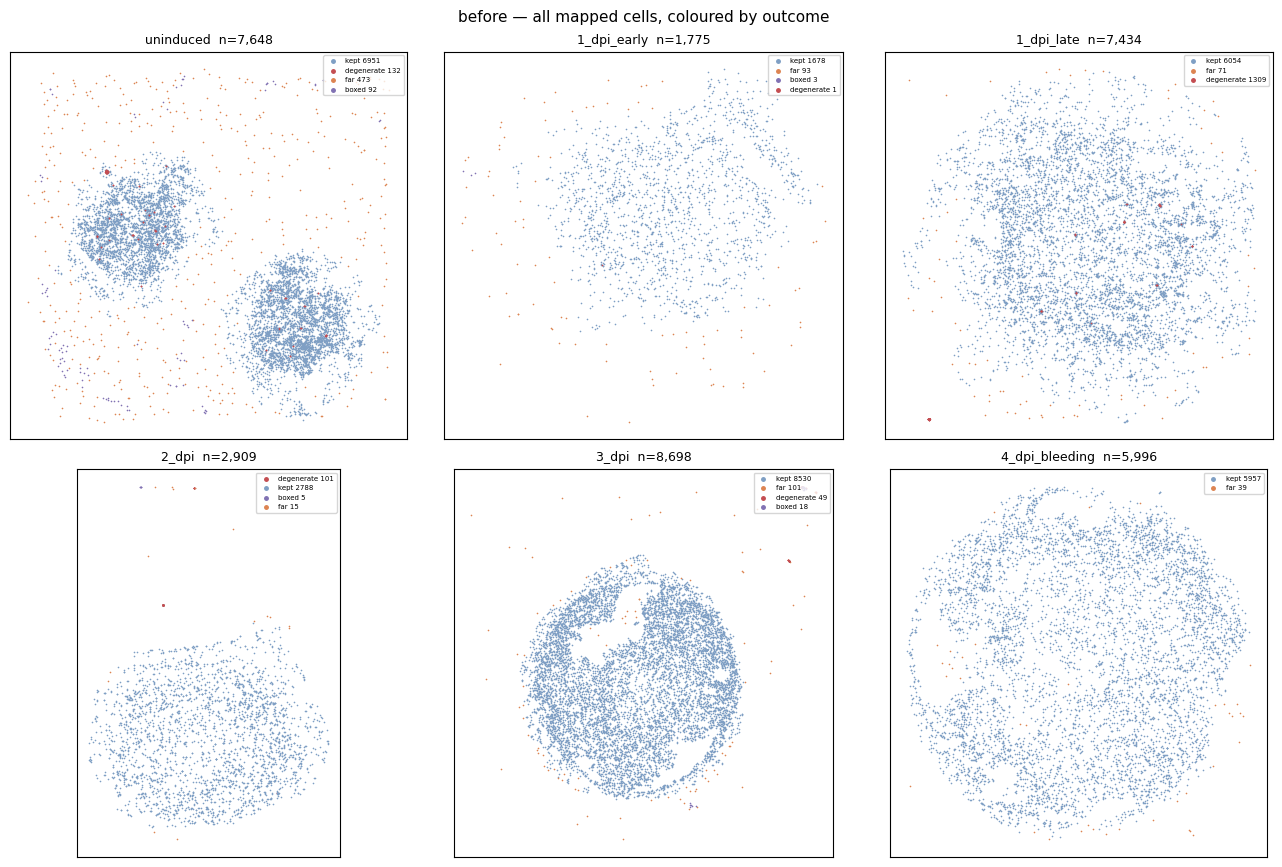

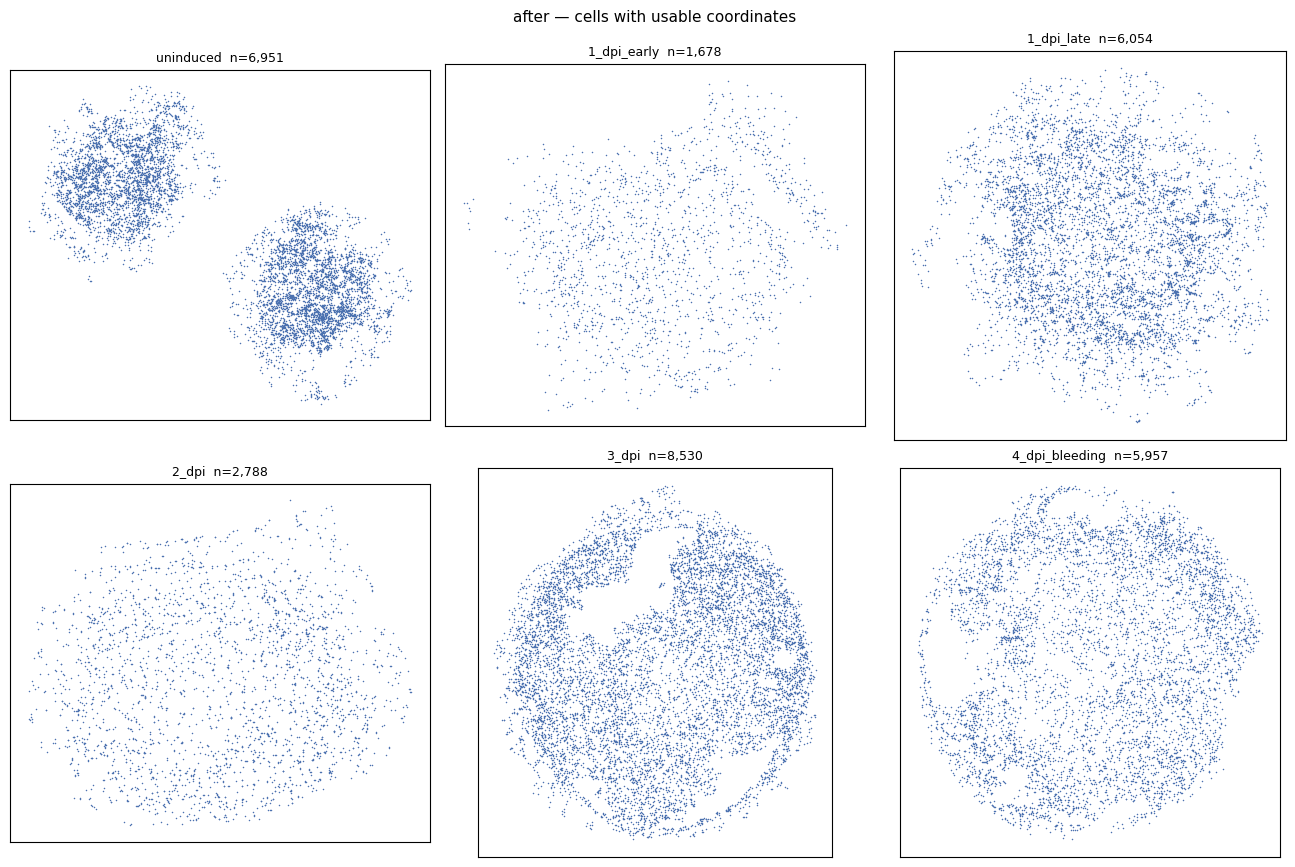

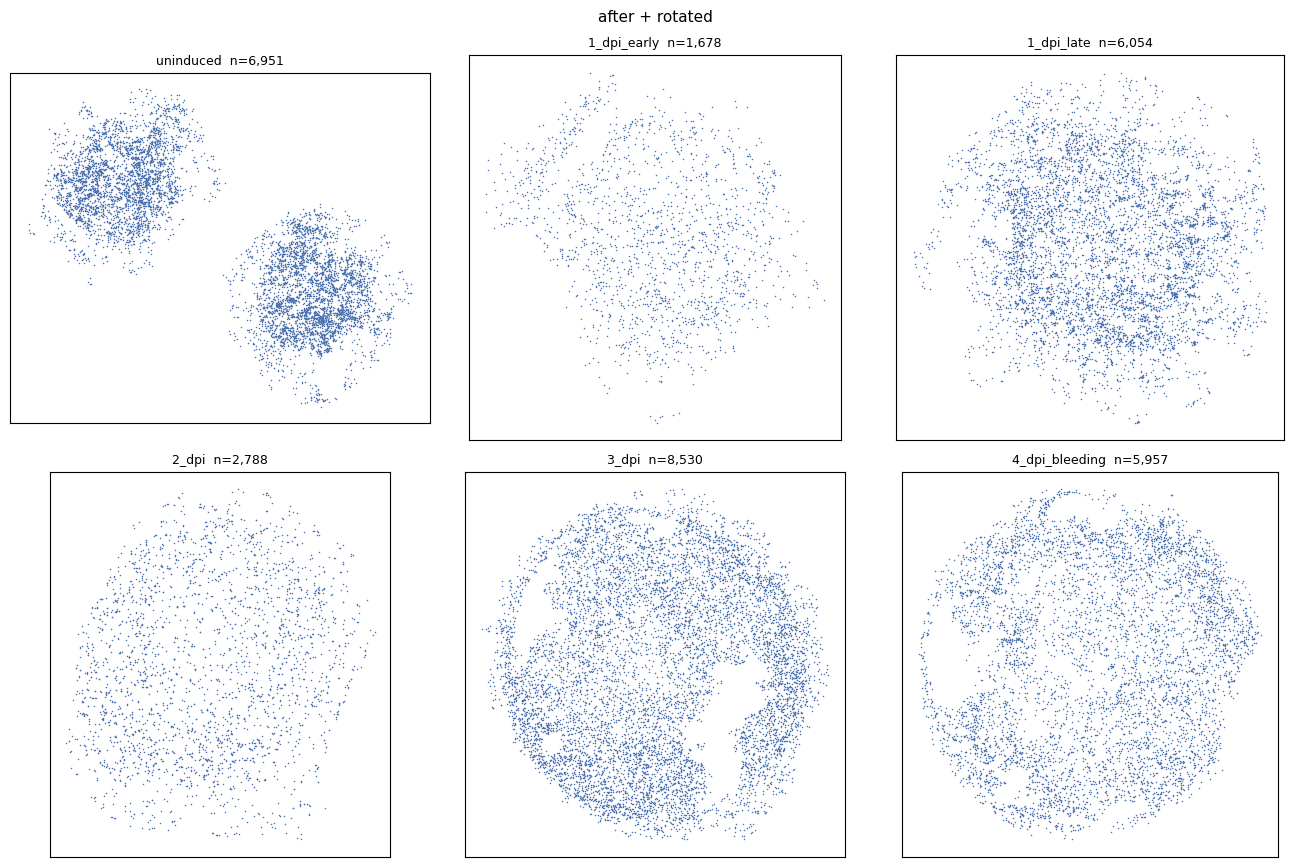

In [14]:
def panel_grid(xs, ys, title, colour_by=None, ncol=3):
    nrow = int(np.ceil(len(TPS)/ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.4*ncol, 4.4*nrow), squeeze=False)
    for i, tp in enumerate(TPS):
        ax = axes[i//ncol][i%ncol]
        m = (obs[TIMEPOINT].astype(str) == tp).values & ~np.isnan(xs)
        if colour_by is None:
            ax.scatter(xs[m], ys[m], s=1.2, c="#4C72B0", linewidths=0)
        else:
            for lev in pd.unique(colour_by[m]):
                q = m & (colour_by == lev).values
                ax.scatter(xs[q], ys[q], s=1.4, linewidths=0,
                           c=COL.get(lev, "#333"), label=f"{lev} {int(q.sum())}")
            ax.legend(fontsize=5, markerscale=3, loc="upper right")
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{tp}  n={int(m.sum()):,}", fontsize=9)
    for k_ in range(len(TPS), nrow*ncol): axes[k_//ncol][k_%ncol].axis("off")
    fig.suptitle(title, fontsize=11); fig.tight_layout(); plt.show()

xa, ya = obs[X].astype(float).values, obs[Y].astype(float).values
panel_grid(np.where(mapped, xa, np.nan), np.where(mapped, ya, np.nan),
           "before — all mapped cells, coloured by outcome", colour_by=reason)
panel_grid(x_qc, y_qc, "after — cells with usable coordinates")
panel_grid(x_rot, y_rot, "after + rotated")

70,363 cells x 36,601 genes
x-like columns: ['x_um_dbscan']
y-like columns: ['y_um_dbscan']
using X=x_um_dbscan  Y=y_um_dbscan  TIMEPOINT=timepoint

unmapped: 22,903 / 70,363 (32.5%)   [mouse: 49%]
                               n  mapped  mapped_%
timepoint sample                                  
menstrual menstrual_mck5a  12794    7619      59.6
          menstrual_mck5b  12795    7962      62.2
          menstrual_mck5c  11548    6999      60.6
secretory secretory_mck6a  13024    9718      74.6
          secretory_mck6b  12685    9444      74.5
          secretory_mck6c   7517    5718      76.1

coordinate ranges per puck:
                           x_min   x_max  y_min   y_max
timepoint sample                                       
menstrual menstrual_mck5a   89.0  5886.0  201.0  5845.0
          menstrual_mck5b   83.0  5892.0   45.0  5818.0
          menstrual_mck5c  118.0  5810.0  205.0  5851.0
secretory secretory_mck6a  468.0  5840.0  456.0  5749.0
          secretory_mck6b  45

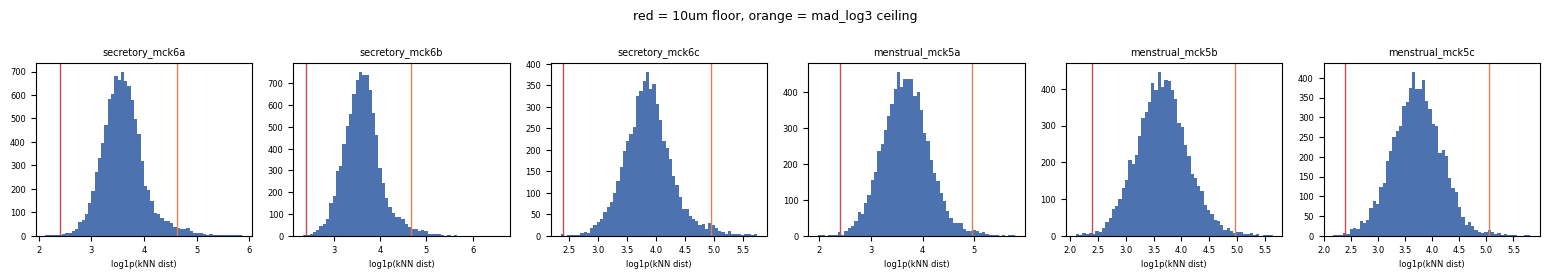

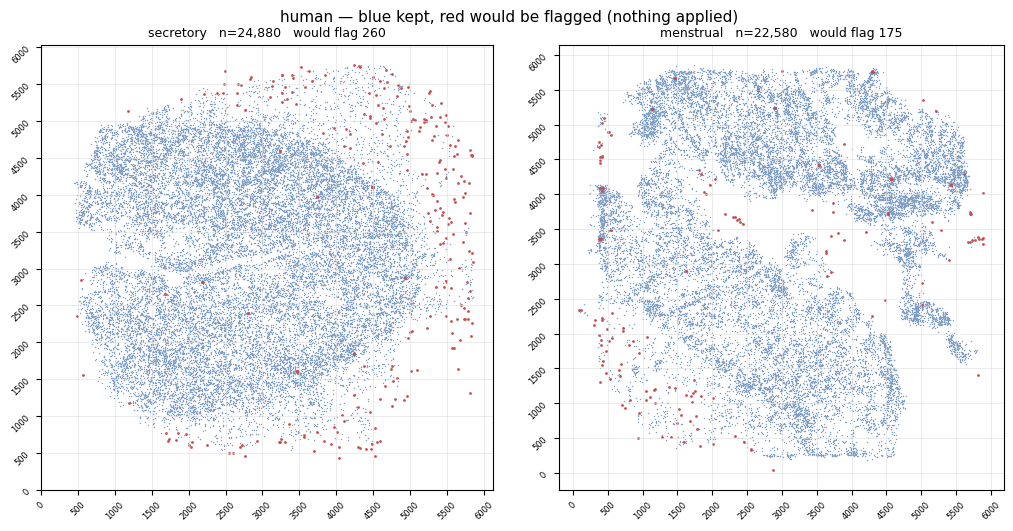

In [15]:
# ============================================================================
# HUMAN spatial diagnostic -- does it need any of the mouse treatment?
# Read-only: nothing is filtered, nothing is written.
# ============================================================================
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scanpy as sc
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.neighbors import NearestNeighbors
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60)

REPO = Path("/n/eddy_lab/users/nhilgert/xmens_final")
H    = sc.read_h5ad(REPO/"data/interim/qc_passed_human.h5ad")
o    = H.obs
K, FLOOR_UM, N_MADS = 5, 10.0, 3.0

cand_x = [c for c in o.columns if c.lower().startswith("x_")]
cand_y = [c for c in o.columns if c.lower().startswith("y_")]
print(f"{H.n_obs:,} cells x {H.n_vars:,} genes")
print(f"x-like columns: {cand_x}\ny-like columns: {cand_y}")
X = "x_um_dbscan" if "x_um_dbscan" in o else (cand_x[0] if cand_x else None)
Y = "y_um_dbscan" if "y_um_dbscan" in o else (cand_y[0] if cand_y else None)
assert X and Y, "no spatial coordinate columns found"
SAMPLE = "sample"
TIMEPOINT = "timepoint" if "timepoint" in o else ("phase" if "phase" in o else SAMPLE)
print(f"using X={X}  Y={Y}  TIMEPOINT={TIMEPOINT}\n")

mapped = (o[X].notna() & o[Y].notna()).values
print(f"unmapped: {int((~mapped).sum()):,} / {H.n_obs:,} ({100*(~mapped).mean():.1f}%)   [mouse: 49%]")
inv = (o.assign(mapped=mapped).groupby([TIMEPOINT, SAMPLE], observed=True)
       .agg(n=(X,"size"), mapped=("mapped","sum")))
inv["mapped_%"] = (100*inv.mapped/inv.n).round(1); print(inv.to_string())

print("\ncoordinate ranges per puck:")
print((o[mapped].groupby([TIMEPOINT, SAMPLE], observed=True)
       .agg(x_min=(X,"min"), x_max=(X,"max"), y_min=(Y,"min"), y_max=(Y,"max")).round(0)).to_string())

def knn_mean_dist(xy, k=K):
    if xy.shape[0] <= k+1: return np.zeros(xy.shape[0])
    nn = NearestNeighbors(n_neighbors=k+1).fit(xy); d,_ = nn.kneighbors(xy)
    return d[:,1:].mean(axis=1)

score = pd.Series(np.nan, index=o.index)
for s in o.loc[mapped, SAMPLE].astype(str).unique():
    m = mapped & (o[SAMPLE].astype(str) == s).values
    score.loc[m] = knn_mean_dist(o.loc[m, [X, Y]].to_numpy(float))
key  = (o[SAMPLE].astype(str) + "|" + o[X].astype(str) + "|" + o[Y].astype(str))
n_at = key.map(key[mapped].value_counts()).fillna(0)

rows = []
for s in o.loc[mapped, SAMPLE].astype(str).unique():
    m = mapped & (o[SAMPLE].astype(str) == s).values
    d = score[m].to_numpy(float)
    lv = np.log1p(d); med_, mad_ = np.median(lv), np.median(np.abs(lv-np.median(lv)))
    thr_all = float(np.expm1(med_ + N_MADS*1.4826*mad_))
    clean = d[d >= FLOOR_UM]
    if len(clean) > 10:
        lc = np.log1p(clean); mc, ac = np.median(lc), np.median(np.abs(lc-np.median(lc)))
        thr_clean = float(np.expm1(mc + N_MADS*1.4826*ac))
    else: thr_clean = np.nan
    rows.append({"sample": s, "n": int(m.sum()),
                 "dup_coords": int((mapped & (n_at > 1).values & m).sum()),
                 "d<10um": int((d < FLOOR_UM).sum()), "d==0": int((d == 0).sum()),
                 "median_um": round(float(np.median(d)), 1),
                 "madlog3_all": round(thr_all, 1),
                 "madlog3_clean": round(thr_clean, 1) if thr_clean == thr_clean else np.nan,
                 "would_drop": int((d > (thr_clean if thr_clean==thr_clean else thr_all)).sum())})
diag = pd.DataFrame(rows).set_index("sample")
print("\nper-puck diagnostic  (madlog3_all vs _clean diverging = pile-ups corrupting it)")
print(diag.to_string())
print(f"\nTOTALS  degenerate-ish: {int(diag['d<10um'].sum()):,}   "
      f"upper-tail: {int(diag['would_drop'].sum()):,}   of {int(mapped.sum()):,} mapped")

smp = list(o.loc[mapped, SAMPLE].astype(str).unique())
fig, axes = plt.subplots(1, len(smp), figsize=(2.6*len(smp), 2.8), squeeze=False)
for ax, s in zip(axes[0], smp):
    d = score[mapped & (o[SAMPLE].astype(str) == s).values].to_numpy(float)
    ax.hist(np.log1p(d), bins=60, color="#4C72B0")
    ax.axvline(np.log1p(FLOOR_UM), color="#C44E52", lw=1)
    t = diag.loc[s, "madlog3_clean"]
    if t == t: ax.axvline(np.log1p(t), color="#DD8452", lw=1)
    ax.set_title(s, fontsize=7); ax.tick_params(labelsize=6)
    ax.set_xlabel("log1p(kNN dist)", fontsize=6)
fig.suptitle("red = 10um floor, orange = mad_log3 ceiling", fontsize=9)
fig.tight_layout(); plt.show()

tps = list(pd.unique(o.loc[mapped, TIMEPOINT].astype(str)))
ncol = min(3, len(tps)); nrow = int(np.ceil(len(tps)/ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(5.2*ncol, 5.2*nrow), squeeze=False)
for i, tp in enumerate(tps):
    ax = axes[i//ncol][i%ncol]
    m = mapped & (o[TIMEPOINT].astype(str) == tp).values
    d = score[m].to_numpy(float); sub = o.loc[m]
    flag = (d < FLOOR_UM) | (d > np.nanmax([diag.loc[s, "madlog3_clean"]
            for s in sub[SAMPLE].astype(str).unique()]))
    ax.scatter(sub.loc[~flag, X], sub.loc[~flag, Y], s=1.0, c="#7f9fc4", linewidths=0)
    ax.scatter(sub.loc[flag, X],  sub.loc[flag, Y],  s=4, c="#C44E52", linewidths=0)
    step = max(round((max(sub[X].max()-sub[X].min(), sub[Y].max()-sub[Y].min())/10)/500)*500, 250)
    ax.set_xticks(np.arange(np.floor(sub[X].min()/step)*step, sub[X].max()+step, step))
    ax.set_yticks(np.arange(np.floor(sub[Y].min()/step)*step, sub[Y].max()+step, step))
    ax.grid(True, lw=.4, c="#dddddd"); ax.tick_params(labelsize=6, rotation=45)
    ax.set_aspect("equal")
    ax.set_title(f"{tp}   n={int(m.sum()):,}   would flag {int(flag.sum())}", fontsize=9)
for k_ in range(len(tps), nrow*ncol): axes[k_//ncol][k_%ncol].axis("off")
fig.suptitle("human — blue kept, red would be flagged (nothing applied)", fontsize=11)
fig.tight_layout(); plt.show()

coarse
endometrial fibroblasts    17677
decidual cells             13855
epithelial cells            8494
unlabeled                   3138
immune cells                2404
perivascular cells          1006
smooth muscle cells          886

suggested_rot = degrees CCW to bring the epithelial axis to 90deg (up)

                    n  n_epi    cx    cy  epi_offset_um  epi_axis_deg  suggested_rot
sample                                                                              
secretory_mck6a  9718   1444  2769  3211            226         -18.3          198.3
secretory_mck6b  9444   1403  2790  3220            238         -50.3          230.3
secretory_mck6c  5718    893  2773  3237            289         -61.1          241.1
menstrual_mck5a  7619   1651  3061  3772            355          95.9           84.1
menstrual_mck5b  7962   1661  3050  3772            455          97.8           82.2
menstrual_mck5c  6999   1442  3060  3726            275         102.0           78.0

NOTE sma

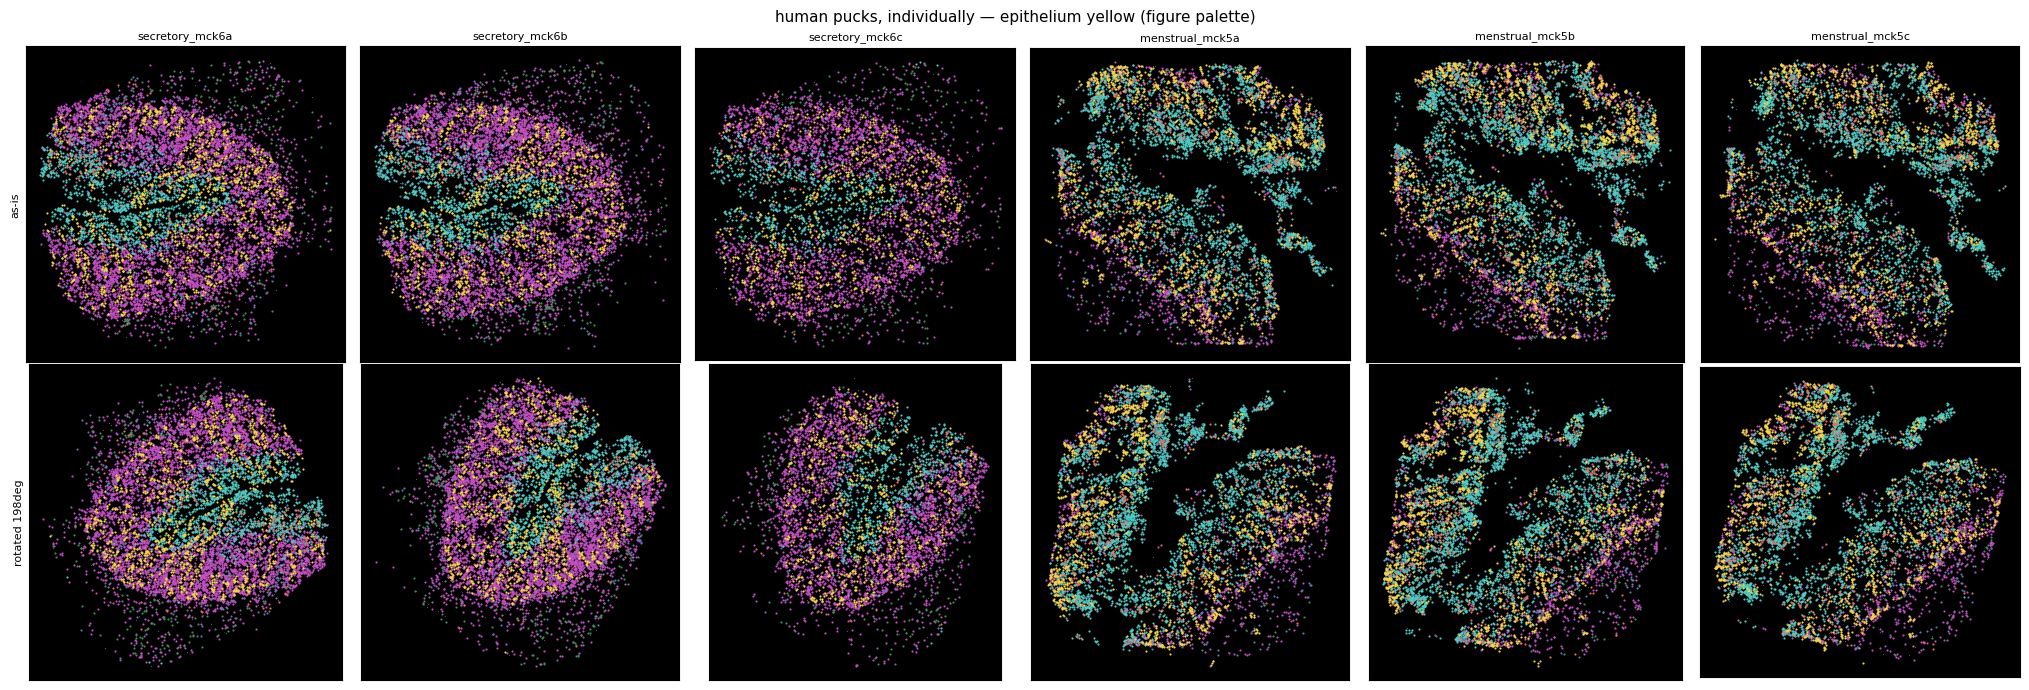

In [17]:
# ---- HUMAN: per-puck view + a DERIVED rotation angle ------------------------
SUB_H = Path("/n/eddy_lab/users/nhilgert/decidualization/revisions/adatas/submission")
TARGET_DEG = 180        # where the epithelial axis should end up (90 = up)

def _canon(s): return s.astype(str).str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
def _key(d):
    return _canon(d["sample"]) + "||" + \
           d["cell_barcode"].astype(str).str.replace(r"-\d+$", "", regex=True)

ref = sc.read_h5ad(SUB_H/"20251008_Cevrim_Human_All_Cells.h5ad", backed="r").obs.copy()
ref["k"] = _key(ref)
lab = _key(o).map(ref.set_index("k")["cell_type_annotations"]).astype(object)
o = o.assign(coarse=lab.where(lab.notna(), "unlabeled").values)
print(o.loc[mapped, "coarse"].value_counts().to_string())

EPI = "epithelial cells"; rows = []
for s in o.loc[mapped, SAMPLE].astype(str).unique():
    m = mapped & (o[SAMPLE].astype(str) == s).values
    e = m & (o["coarse"] == EPI).values
    cx, cy = float(o.loc[m, X].median()), float(o.loc[m, Y].median())
    if e.sum() < 30:
        rows.append({"sample": s, "n": int(m.sum()), "n_epi": int(e.sum())}); continue
    ex, ey = float(o.loc[e, X].median()), float(o.loc[e, Y].median())
    ang = float(np.degrees(np.arctan2(ey - cy, ex - cx)))
    rows.append({"sample": s, "n": int(m.sum()), "n_epi": int(e.sum()),
                 "cx": round(cx), "cy": round(cy),
                 "epi_offset_um": round(float(np.hypot(ex-cx, ey-cy))),
                 "epi_axis_deg": round(ang, 1),
                 "suggested_rot": round((TARGET_DEG - ang) % 360, 1)})
rot = pd.DataFrame(rows).set_index("sample")
print("\nsuggested_rot = degrees CCW to bring the epithelial axis to 90deg (up)\n")
print(rot.to_string())
print("\nNOTE small epi_offset_um = epithelium near-centred, axis ill-defined -> eyeball it.")

def rotate_about(x, y, deg, cx, cy):
    if deg % 360 == 0: return x.copy(), y.copy()
    r = np.radians(deg); ca, sa = np.cos(r), np.sin(r)
    dx, dy = x - cx, y - cy
    return cx + ca*dx - sa*dy, cy + sa*dx + ca*dy

CT_COL = {"decidual cells":"#4ECDC4","endometrial fibroblasts":"#C44FC4",
          "epithelial cells":"#F5D547","immune cells":"#E8705F",
          "perivascular cells":"#5B7DB1","smooth muscle cells":"#3E8E5A",
          "unlabeled":"#666666"}
smp = list(o.loc[mapped, SAMPLE].astype(str).unique())
fig, axes = plt.subplots(2, len(smp), figsize=(3.4*len(smp), 7.0), squeeze=False)
for j, s in enumerate(smp):
    m = mapped & (o[SAMPLE].astype(str) == s).values
    deg = rot["suggested_rot"].get(s, 0.0); deg = 0.0 if deg != deg else deg
    cx, cy = float(o.loc[m, X].median()), float(o.loc[m, Y].median())
    xr, yr = rotate_about(o.loc[m, X].to_numpy(float), o.loc[m, Y].to_numpy(float), deg, cx, cy)
    for row, (xs, ys, ttl) in enumerate([(o.loc[m, X].values, o.loc[m, Y].values, "as-is"),
                                         (xr, yr, f"rotated {deg:.0f}deg")]):
        ax = axes[row][j]; cc = o.loc[m, "coarse"].astype(str).values
        for ct in ["unlabeled","endometrial fibroblasts","decidual cells","immune cells",
                   "perivascular cells","smooth muscle cells","epithelial cells"]:
            q = cc == ct
            if q.sum():
                ax.scatter(np.asarray(xs)[q], np.asarray(ys)[q],
                           s=(0.6 if ct=="unlabeled" else 2.4), c=CT_COL[ct], linewidths=0)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_facecolor("#000")
        if row == 0: ax.set_title(s, fontsize=8)
        if j == 0: ax.set_ylabel(ttl, fontsize=8)
fig.suptitle("human pucks, individually — epithelium yellow (figure palette)", fontsize=11)
fig.tight_layout(); plt.show()

           n_pucks     per_puck_deg  mean_offset_um  axis_deg  suggested_rot
timepoint                                                                   
secretory        3  [-18, -50, -61]             251     -43.4          133.4
menstrual        3    [96, 98, 102]             362      98.6          351.4


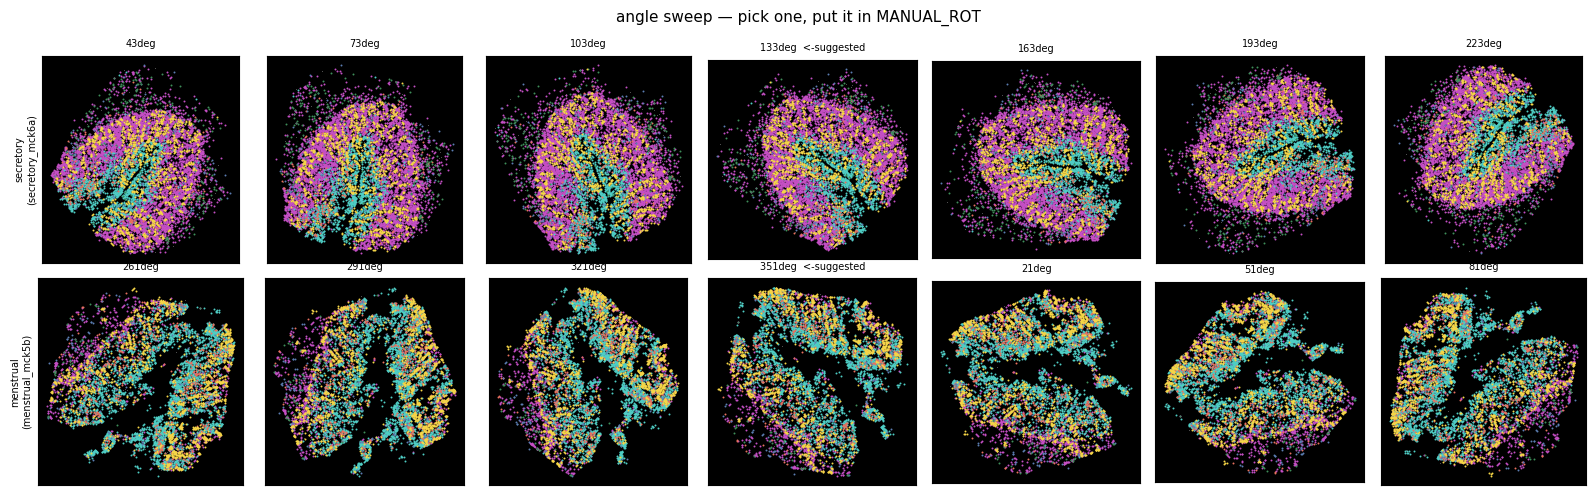

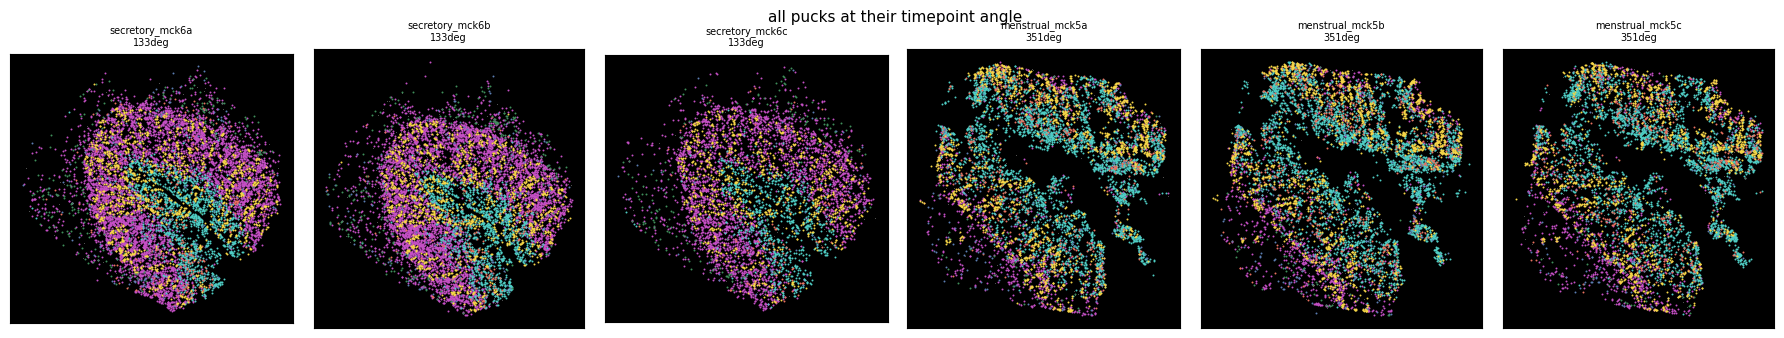

In [18]:
# ---- HUMAN rotation, per TIMEPOINT ------------------------------------------
TARGET_DEG = 90.0
EPI = "epithelial cells"

per_puck = {}
for s in o.loc[mapped, SAMPLE].astype(str).unique():
    m = mapped & (o[SAMPLE].astype(str) == s).values
    e = m & (o["coarse"] == EPI).values
    if e.sum() < 30: continue
    cx, cy = float(o.loc[m, X].median()), float(o.loc[m, Y].median())
    ex, ey = float(o.loc[e, X].median()), float(o.loc[e, Y].median())
    per_puck[s] = (float(np.degrees(np.arctan2(ey-cy, ex-cx))),
                   float(np.hypot(ex-cx, ey-cy)),
                   o.loc[m, TIMEPOINT].astype(str).iloc[0])

rows, tp_axis = [], {}
for tp in pd.unique(o.loc[mapped, TIMEPOINT].astype(str)):
    angs = [a for a, _, t in per_puck.values() if t == tp]
    offs = [d for _, d, t in per_puck.values() if t == tp]
    if not angs: continue
    r = np.radians(angs)
    mean_ang = float(np.degrees(np.arctan2(np.sin(r).mean(), np.cos(r).mean())))
    tp_axis[tp] = mean_ang
    rows.append({"timepoint": tp, "n_pucks": len(angs),
                 "per_puck_deg": [round(a) for a in angs],
                 "mean_offset_um": round(float(np.mean(offs))),
                 "axis_deg": round(mean_ang, 1),
                 "suggested_rot": round((TARGET_DEG - mean_ang) % 360, 1)})
print(pd.DataFrame(rows).set_index("timepoint").to_string())

MANUAL_ROT = {}          # nudge here after the sweep, e.g. {"secretory": 205.0}

def final_rot(tp):
    if tp in MANUAL_ROT: return MANUAL_ROT[tp]
    return (TARGET_DEG - tp_axis[tp]) % 360 if tp in tp_axis else 0.0

def rotate_about(x, y, deg, cx, cy):
    if deg % 360 == 0: return np.asarray(x).copy(), np.asarray(y).copy()
    r = np.radians(deg); ca, sa = np.cos(r), np.sin(r)
    dx, dy = np.asarray(x)-cx, np.asarray(y)-cy
    return cx + ca*dx - sa*dy, cy + sa*dx + ca*dy

CT_COL = {"decidual cells":"#4ECDC4","endometrial fibroblasts":"#C44FC4",
          "epithelial cells":"#F5D547","immune cells":"#E8705F",
          "perivascular cells":"#5B7DB1","smooth muscle cells":"#3E8E5A",
          "unlabeled":"#555555"}
DRAW = ["unlabeled","endometrial fibroblasts","decidual cells","immune cells",
        "perivascular cells","smooth muscle cells","epithelial cells"]

def draw(ax, m, deg):
    cx, cy = float(o.loc[m, X].median()), float(o.loc[m, Y].median())
    xr, yr = rotate_about(o.loc[m, X].values, o.loc[m, Y].values, deg, cx, cy)
    cc = o.loc[m, "coarse"].astype(str).values
    for ct in DRAW:
        q = cc == ct
        if q.sum(): ax.scatter(xr[q], yr[q], s=(0.5 if ct=="unlabeled" else 2.0),
                               c=CT_COL[ct], linewidths=0)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.set_facecolor("#000")

# SWEEP -- pick the angle off this
tps = [t for t in pd.unique(o.loc[mapped, TIMEPOINT].astype(str)) if t in tp_axis]
STEP, N = 30, 7
fig, axes = plt.subplots(len(tps), N, figsize=(2.3*N, 2.5*len(tps)), squeeze=False)
for i, tp in enumerate(tps):
    reps = [s for s, (_, _, t) in per_puck.items() if t == tp]
    rep = max(reps, key=lambda s: (mapped & (o[SAMPLE].astype(str) == s).values).sum())
    m = mapped & (o[SAMPLE].astype(str) == rep).values
    base = final_rot(tp)
    for j in range(N):
        deg = (base + (j - N//2)*STEP) % 360
        ax = axes[i][j]; draw(ax, m, deg)
        ax.set_title(f"{deg:.0f}deg" + ("  <-suggested" if j == N//2 else ""), fontsize=7)
        if j == 0: ax.set_ylabel(f"{tp}\n({rep})", fontsize=7)
fig.suptitle("angle sweep — pick one, put it in MANUAL_ROT", fontsize=11)
fig.tight_layout(); plt.show()

# all pucks at the chosen timepoint angle
smp = list(o.loc[mapped, SAMPLE].astype(str).unique())
fig, axes = plt.subplots(1, len(smp), figsize=(3.0*len(smp), 3.4), squeeze=False)
for ax, s in zip(axes[0], smp):
    m = mapped & (o[SAMPLE].astype(str) == s).values
    tp = o.loc[m, TIMEPOINT].astype(str).iloc[0]
    draw(ax, m, final_rot(tp)); ax.set_title(f"{s}\n{final_rot(tp):.0f}deg", fontsize=7)
fig.suptitle("all pucks at their timepoint angle", fontsize=11)
fig.tight_layout(); plt.show()

## 10. Write

Original coordinates are left untouched; the QC'd and rotated versions are added
alongside, so every step stays auditable and reversible.

In [ ]:
adata.obs["spatial_qc_reason"] = pd.Categorical(reason.values, categories=ORDER)
adata.obs["x_um_qc"],  adata.obs["y_um_qc"]  = x_qc,  y_qc
adata.obs["x_um_rot"], adata.obs["y_um_rot"] = x_rot, y_rot
adata.obsm["spatial"]     = np.c_[x_qc,  y_qc]      # QC'd, unrotated
adata.obsm["spatial_rot"] = np.c_[x_rot, y_rot]     # QC'd + oriented
adata.uns["spatial_qc"] = {
    "k": K, "floor_um": FLOOR_UM, "max_at_coord": MAX_AT_COORD, "n_mads": N_MADS,
    "mad_group": MAD_GROUP, "log_scale": True, "action": "blank",
    "thresholds_um": {k_: round(v, 1) for k_, v in thr.items()},
    # h5py can't store lists of dicts -- JSON round-trips cleanly
    "exclusions_json": json.dumps(EXCL), "rotations_json": json.dumps(ROT),
}
p = REPO/OUT_H5AD; p.parent.mkdir(parents=True, exist_ok=True)
adata.write_h5ad(p)
print(f"wrote {p}\n  {adata.n_obs:,} cells (unchanged), "
      f"{int(kept.sum()):,} with coordinates")
print("  obs: spatial_qc_reason, x_um_qc/y_um_qc, x_um_rot/y_um_rot")
print("  obsm: spatial (QC'd), spatial_rot (QC'd + oriented)")
print("  uns['spatial_qc']: every parameter used")
print("\nDownstream: spatial analyses should use obsm['spatial_rot'] and drop NaN rows.")